# 05 - Feature engineering

The documented feature dictionary and the within-participant statistics for each feature.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
M = ROOT / 'results' / 'metrics'; F = ROOT / 'results' / 'figures'; P = ROOT / 'data' / 'processed'
pd.read_csv(P/'feature_dictionary.csv')

,feature,dataset,modality,unit,source,transformation,note
0,ecg_hr,QoL_Stress,ECG,bpm,"ecg.csv: waveform_samples (30 s, 250 Hz verified)",NeuroKit2 ecg_clean -> ecg_peaks (artefact-cor...,NaN
1,ecg_rmssd,QoL_Stress,ECG,ms,"ecg.csv: waveform_samples (30 s, 250 Hz verified)",NeuroKit2 ecg_clean -> ecg_peaks (artefact-cor...,ultra-short (30 s) HRV
2,ecg_sdnn,QoL_Stress,ECG,ms,"ecg.csv: waveform_samples (30 s, 250 Hz verified)",NeuroKit2 ecg_clean -> ecg_peaks (artefact-cor...,30-s SDNN has low reliability
3,ecg_pnn50,QoL_Stress,ECG,%,"ecg.csv: waveform_samples (30 s, 250 Hz verified)",NeuroKit2 ecg_clean -> ecg_peaks (artefact-cor...,~30 beats: coarse resolution
4,ecg_hr_range,QoL_Stress,ECG,bpm,"ecg.csv: waveform_samples (30 s, 250 Hz verified)",NeuroKit2 ecg_clean -> ecg_peaks (artefact-cor...,reflects respiratory sinus arrhythmia
5,eda_scl_mean,QoL_Stress,EDA,device units,"eda.csv: scl_avg, activation, valid_data (~160...",mean SCL over valid rows,unit undocumented
6,eda_scl_std,QoL_Stress,EDA,device units,"eda.csv: scl_avg, activation, valid_data (~160...",SD of SCL over valid rows,NaN
7,eda_scl_slope,QoL_Stress,EDA,units/min,"eda.csv: scl_avg, activation, valid_data (~160...",OLS slope of SCL vs time (row index / 1 Hz),NaN
8,eda_scl_range,QoL_Stress,EDA,device units,"eda.csv: scl_avg, activation, valid_data (~160...",95th - 5th percentile of SCL,NaN
9,eda_resp_rate,QoL_Stress,EDA,responses/min,"eda.csv: scl_avg, activation, valid_data (~160...",sum(activation) / valid minutes,NaN


## Relax vs stress: paired Wilcoxon tests (BH-FDR corrected)

In [2]:
pd.read_csv(M/'qol_paired_tests.csv').round(4)

,feature,modality,n_pairs,median_relax,median_stress,median_diff,wilcoxon_W,p_value,rank_biserial_r,frac_increase,p_fdr
0,ecg_hr,ECG,51,67.1824,68.6261,0.7240,626.0,0.7287,0.0558,0.5294,0.7287
1,ecg_rmssd,ECG,51,44.4305,41.5032,2.4016,597.0,0.5361,0.0995,0.5490,0.6186
2,ecg_sdnn,ECG,51,52.9983,63.1792,9.7109,416.0,0.0206,0.3725,0.5686,0.0386
3,ecg_pnn50,ECG,51,22.2222,22.8571,2.5641,514.0,0.2332,0.1937,0.5882,0.3498
4,ecg_hr_range,ECG,51,16.5034,20.0677,2.2139,402.0,0.0144,0.3937,0.6275,0.0309
5,eda_scl_mean,EDA,60,41.2279,39.2268,-0.0169,792.0,0.3652,-0.1344,0.5000,0.4565
6,eda_scl_std,EDA,60,0.7767,1.0738,0.1861,383.0,0.0001,0.5814,0.7167,0.0007
7,eda_scl_slope,EDA,60,-0.1338,-0.3839,-0.3289,659.0,0.0595,-0.2798,0.4000,0.0991
8,eda_scl_range,EDA,60,1.7048,2.6215,0.8357,278.0,0.0000,0.6962,0.8167,0.0000
9,eda_resp_rate,EDA,60,8.4090,8.3019,-0.3467,772.0,0.2924,-0.1563,0.4333,0.3987


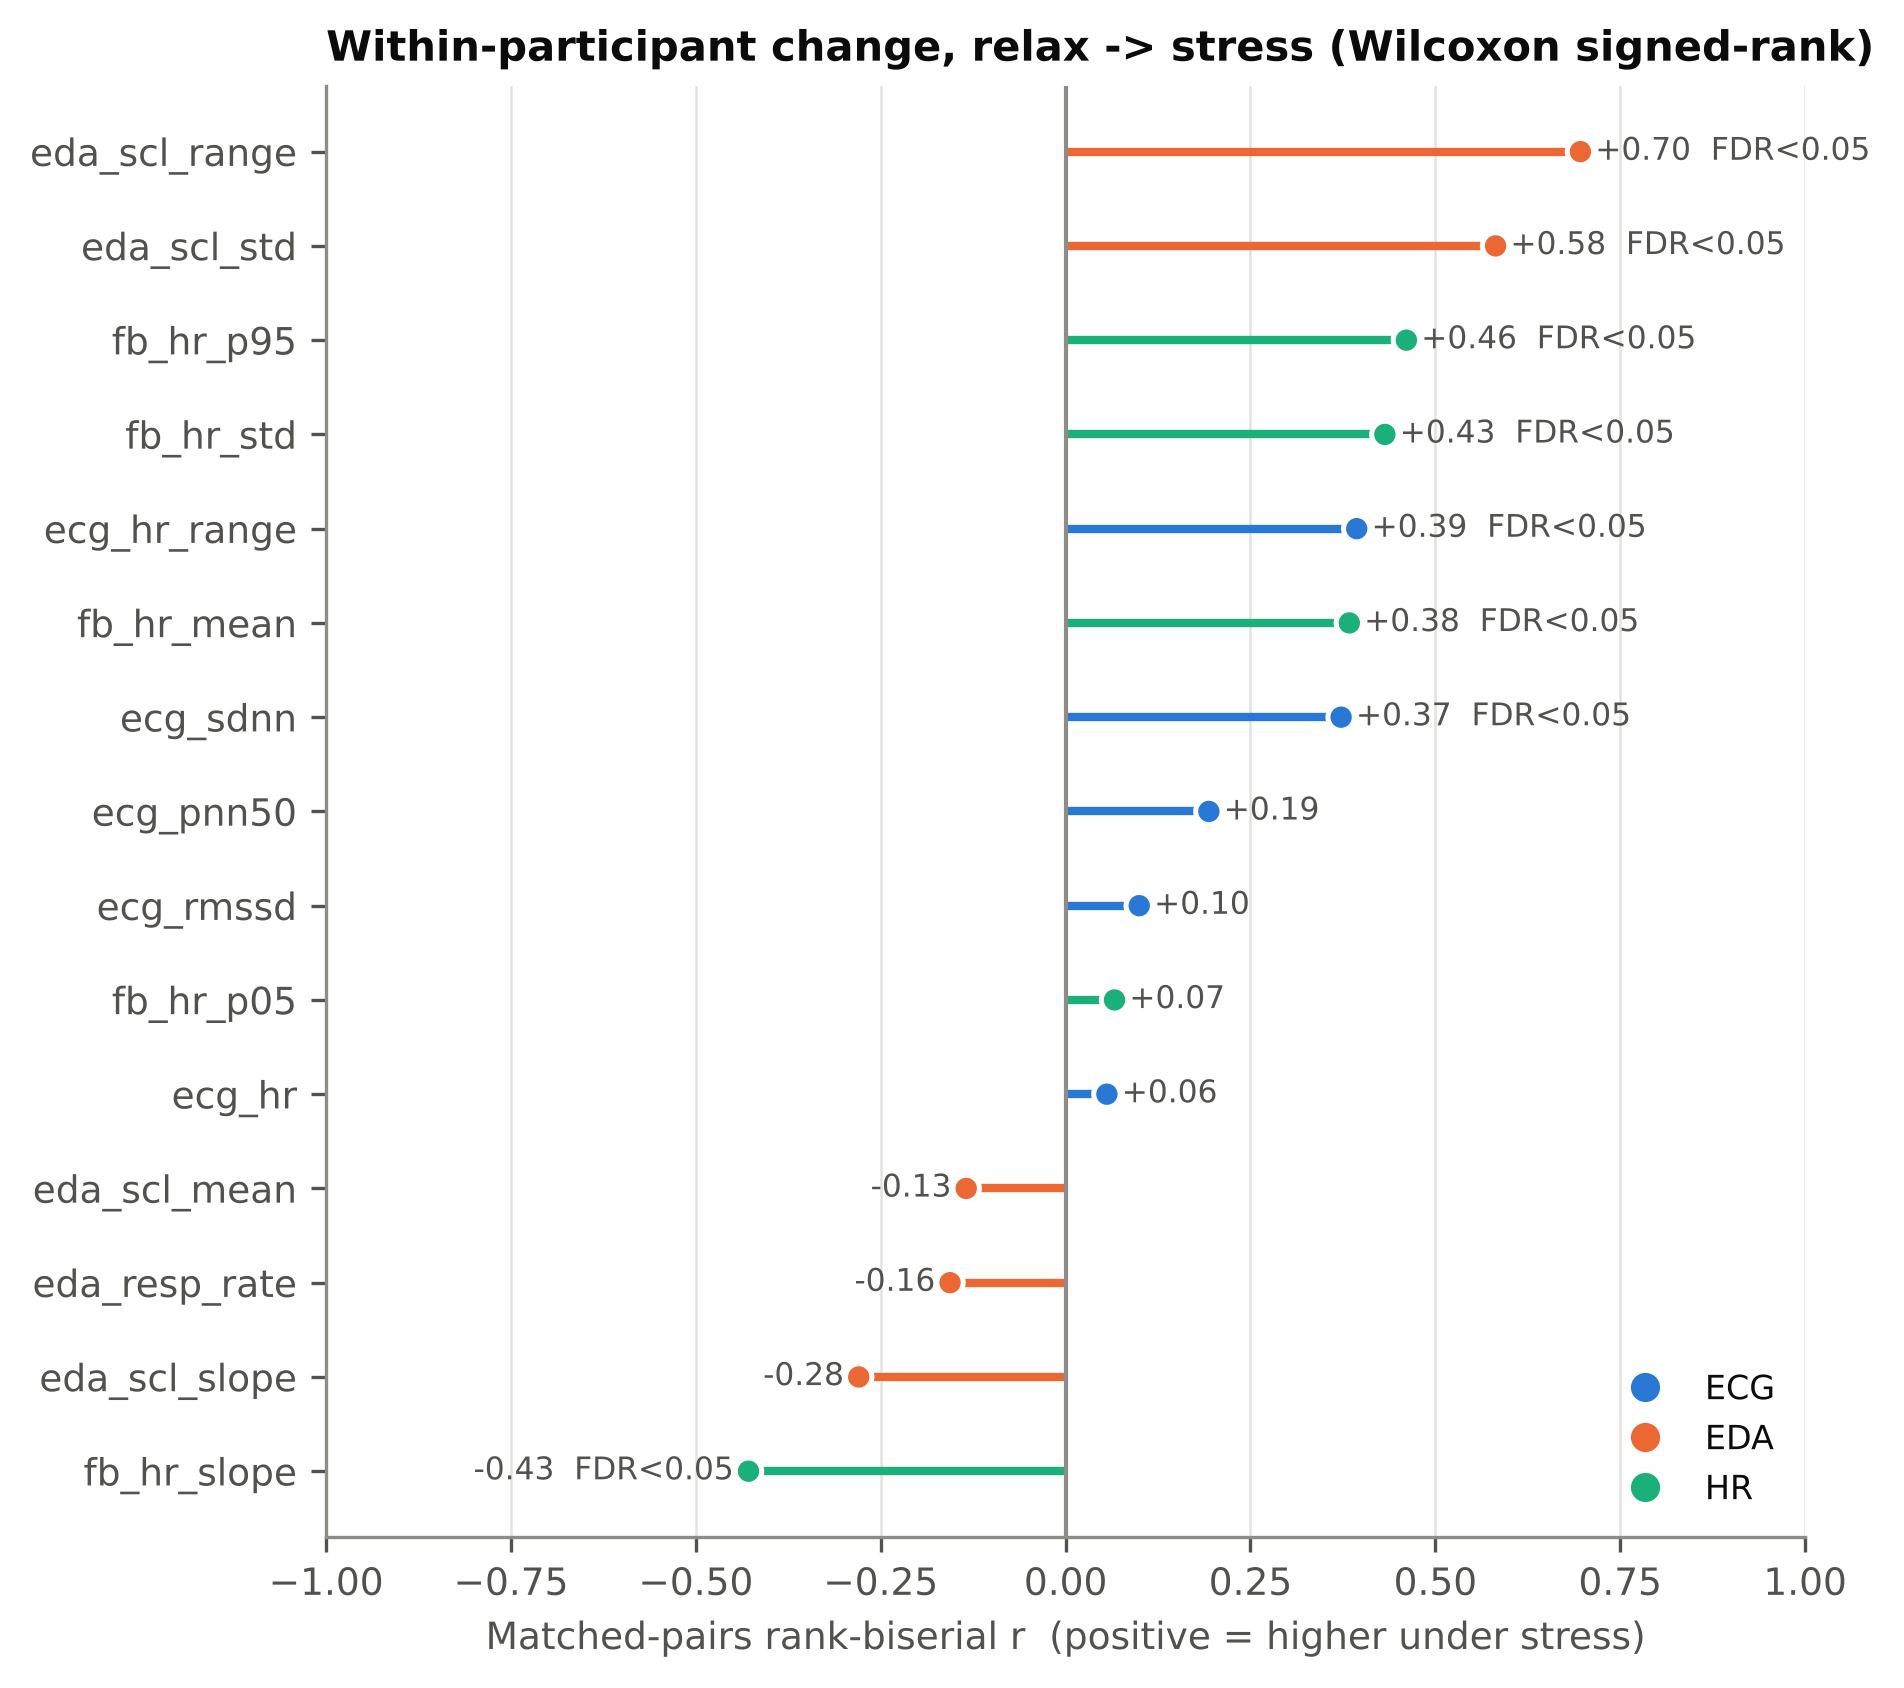

In [3]:
display(Image(F/'qol_paired_effects.png', width=650))

## MMASH: feature-target correlations (exploratory, n = 21)

In [4]:
c = pd.read_csv(M/'mmash_correlations.csv'); c.sort_values('p_value').head(15).round(3)

,target,feature,modality,n,rho,p_value,ci_low,ci_high,p_fdr
13,sleep_efficiency,psych_stai_state,Psychological,21,0.528,0.014,0.049,0.848,0.320
59,waso_min,psych_stai_state,Psychological,21,-0.486,0.026,-0.820,-0.012,0.590
109,psqi,psych_panas_pos_day,Psychological,21,0.446,0.043,-0.047,0.791,0.679
33,tst_min,behav_screen_min,Behavioural,21,0.409,0.066,-0.026,0.685,0.878
82,sleep_fragmentation_index,psych_stai_state,Psychological,21,-0.404,0.069,-0.634,-0.032,0.866
114,psqi,melatonin_before_sleep,Exploratory (not a predictor),20,0.395,0.084,0.010,0.680,0.679
97,psqi,behav_vm_mean,Behavioural,21,0.379,0.090,-0.030,0.698,0.679
43,tst_min,bmi,Exploratory (not a predictor),21,-0.378,0.091,-0.708,0.089,0.878
7,sleep_efficiency,behav_frac_standing,Behavioural,21,-0.369,0.100,-0.686,0.059,0.991
30,tst_min,behav_frac_standing,Behavioural,21,-0.355,0.115,-0.725,0.162,0.878


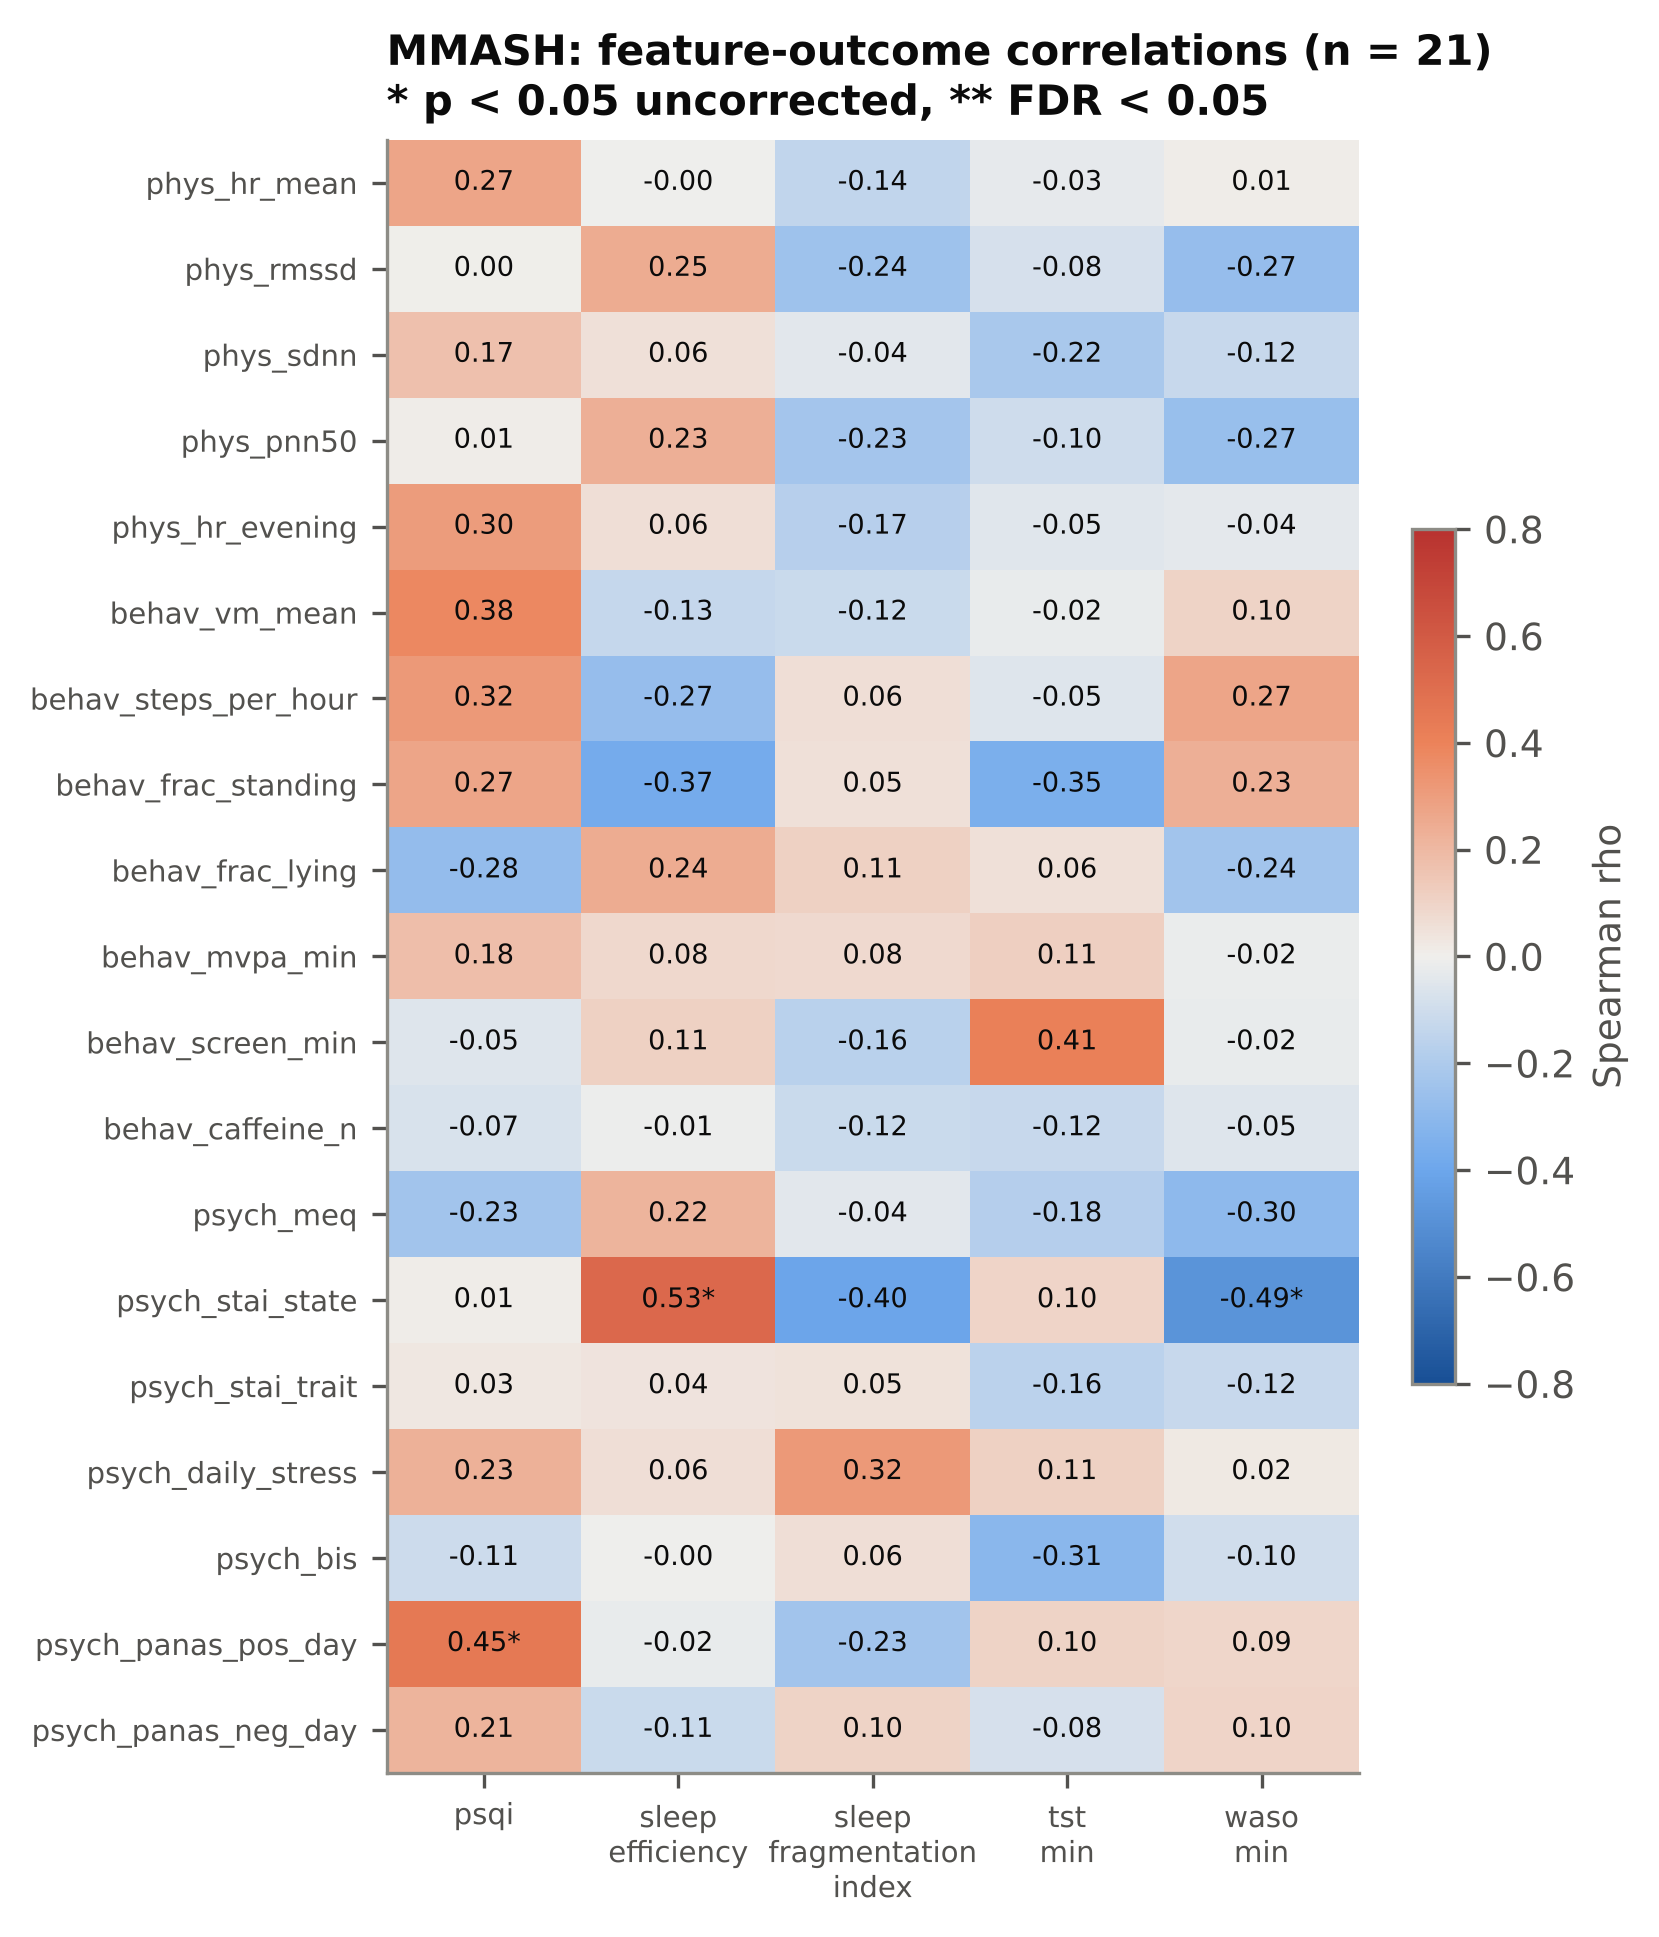

In [5]:
display(Image(F/'mmash_correlation_heatmap.png', width=600))